# Data Loader


## 1. 데이터 준비


In [ ]:
# 공통 데이터 모듈을 프로젝트 루트에서 불러온다.
from pathlib import Path
import sys
import random
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from torchvision.transforms import functional as TF

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from data_loader import (
    read_cub_metadata,
    split_cub_images,
    pad_image,
    build_transforms,
    build_dataloaders,
)

data_dir = project_root / "data" / "CUB_200_2011" / "CUB_200_2011"
image_list, image_labels, class_names = read_cub_metadata(data_dir)

print("이미지 목록 수:", len(image_list))
print(image_list[:3])


In [ ]:
# 메타데이터의 레이블과 클래스 이름을 확인한다.
print("레이블: ", image_labels["1"])
print("클래스: ", class_names[0])


In [ ]:
# 공통 분할 함수로 학습, 검증, 테스트 목록을 생성한다.
train_image_list, val_image_list, test_image_list = split_cub_images(
    data_dir, image_list, image_labels
)
print("train:", len(train_image_list))
print("eval:", len(val_image_list))
print("test:", len(test_image_list))


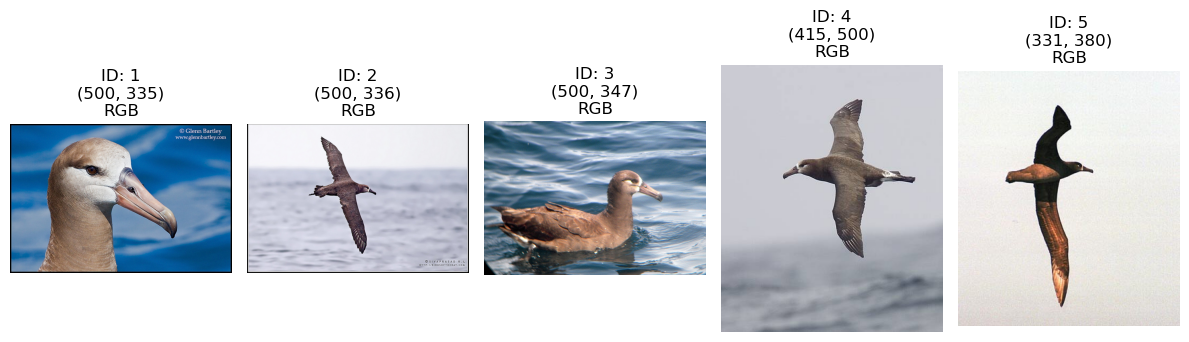

In [4]:
# 원본 사진 5장의 크기와 색상 모드를 확인한다.

fig, axes = plt.subplots(1, 5, figsize=(12, 4))

for ax, row in zip(axes, image_list[:5]):
    image_id, path_name = row.split()
    image_path = data_dir / "images" / path_name

    with Image.open(image_path) as image:
        ax.imshow(image)
        ax.set_title(f"ID: {image_id}\n{image.size}\n{image.mode}")
        ax.axis("off")
        
fig.tight_layout()
plt.show()

## 2. 이미지 전처리

- 크기 비교에서 새의 일부가 잘리는 것을 확인하여 224×224 padding을 선택
- 학습용에는 좌우 반전과 밝기 변화를 적용하고, 평가용에는 무작위 변환을 적용하지 않음
- 정규화는 ImageNet 사전학습 MobileNetV3-Large의 기준값을 사용


In [6]:
# 고정 seed로 비교할 학습 사진 30장을 선택한다.
sample_image_list = random.Random(42).sample(train_image_list, 30)
print("선택한 사진 수:", len(sample_image_list))

# 전처리를 확인할 샘플 사진 한 장을 선택한다.
image_id, image_path = sample_image_list[9].split(maxsplit=1)
image_path = data_dir / "images" / image_path

with Image.open(image_path) as image:
    original = image.copy()

padded = pad_image(original)


선택한 사진 수: 30


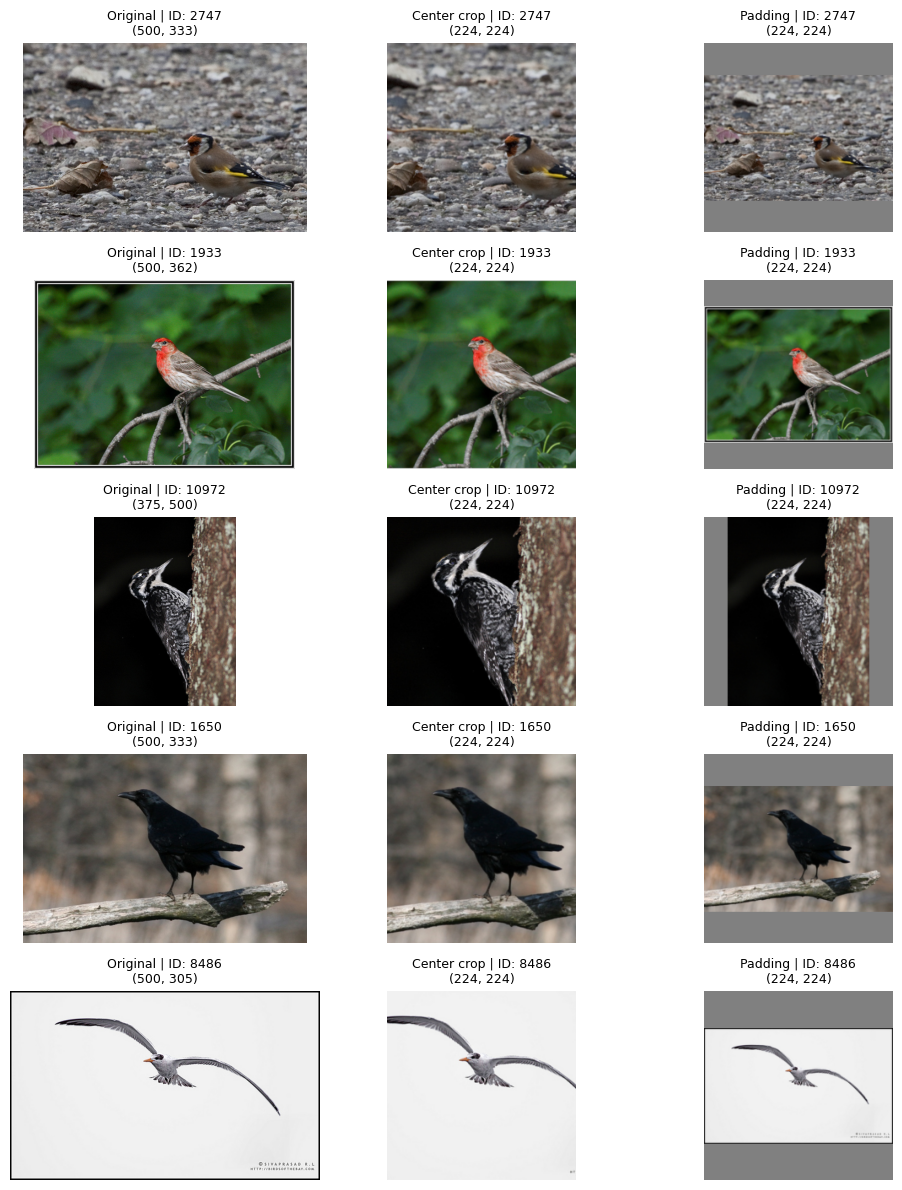

In [7]:
# 원본, 중앙 자르기, padding 결과를 비교한다.

crop_transform = transforms.Compose([
    transforms.Resize(232, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.CenterCrop(224),
])

page = 1 # 페이지당 5장씩 확인한다. 페이지 번호는 0부터 시작한다.
page_image_list = sample_image_list[page * 5:(page + 1) * 5]

fig, axes = plt.subplots(5, 3, figsize=(10, 12))
titles = ["Original", "Center crop", "Padding"]

for row_index, row in enumerate(page_image_list):
    image_id, relative_path = row.split(maxsplit=1)
    image_path = data_dir / "images" / relative_path

    with Image.open(image_path) as image:
        comparison_original = image.copy()

    cropped = crop_transform(comparison_original)
    comparison_padded = pad_image(comparison_original)
    results = [comparison_original, cropped, comparison_padded]

    for ax, result, title in zip(axes[row_index], results, titles):
        ax.imshow(result)
        ax.set_title(f"{title} | ID: {image_id}\n{result.size}", fontsize=9)
        ax.axis("off")

fig.tight_layout()
plt.show()

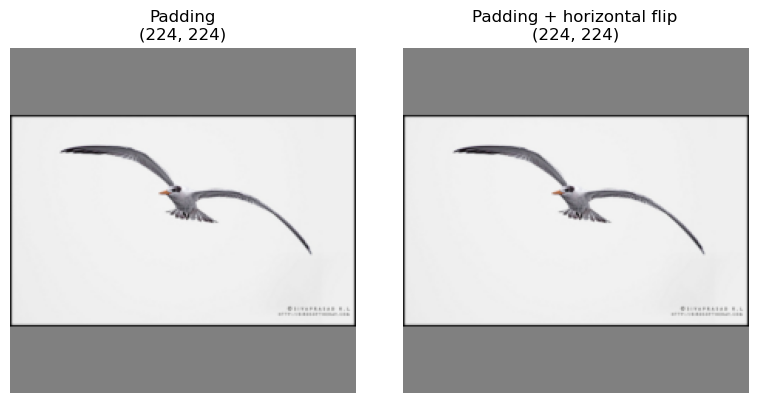

In [8]:
# 이미지를 변환할 때마다 50% 확률로 좌우 반전을 적용한다.

flip_transform = transforms.RandomHorizontalFlip(p=0.5)
flipped = flip_transform(padded)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
images = [padded, flipped]
titles = ["Padding", "Padding + horizontal flip"]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(f"{title}\n{image.size}")
    ax.axis("off")

fig.tight_layout()
plt.show()


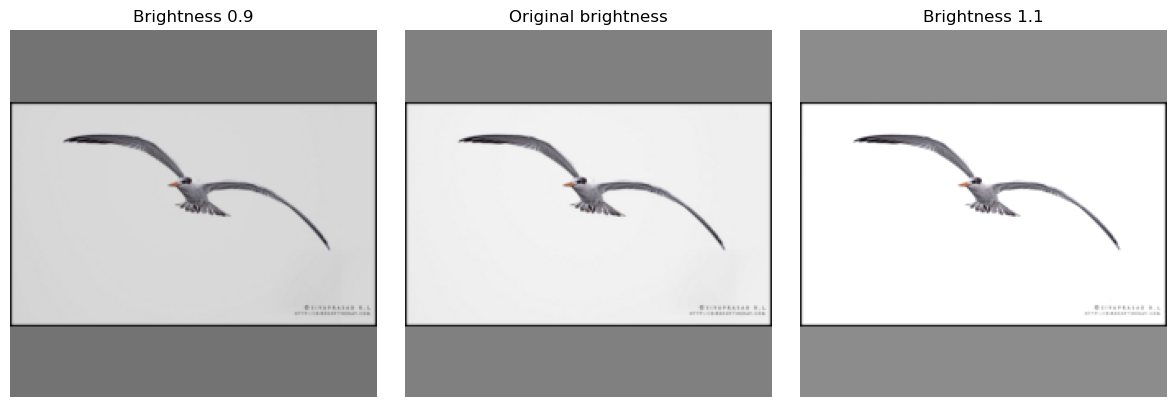

In [9]:
# 밝기 배율 0.9와 1.1을 적용한 결과를 비교한다.
# 비교 이미지의 여백에도 밝기 변화가 적용된다. 학습용 전처리에서는 밝기 조절 후 padding한다.

darker = TF.adjust_brightness(padded, brightness_factor=0.9)
brighter = TF.adjust_brightness(padded, brightness_factor=1.1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
images = [darker, padded, brighter]
titles = ["Brightness 0.9", "Original brightness", "Brightness 1.1"]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

fig.tight_layout()
plt.show()

In [10]:
# 이미지를 텐서로 변환하고 형태, 자료형, 값의 범위를 확인한다.

to_tensor = transforms.ToTensor()
image_tensor = to_tensor(padded)

print("자료형:", type(image_tensor))
print("Shape:", image_tensor.shape)
print("Dtype:", image_tensor.dtype)
print("최솟값:", image_tensor.min().item())
print("최댓값:", image_tensor.max().item())

자료형: <class 'torch.Tensor'>
Shape: torch.Size([3, 224, 224])
Dtype: torch.float32
최솟값: 0.01568627543747425
최댓값: 0.9843137264251709


In [11]:
# ImageNet 사전학습 MobileNetV3-Large의 기준값으로 정규화한다.

normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406], # R, G, B 채널 순서로 지정한다.
    std=[0.229, 0.224, 0.225],
)

normalized_tensor = normalize(image_tensor)

print("Shape:", normalized_tensor.shape)
print("Dtype:", normalized_tensor.dtype)
print("최솟값:", normalized_tensor.min().item())
print("최댓값:", normalized_tensor.max().item())

Shape: torch.Size([3, 224, 224])
Dtype: torch.float32
최솟값: -2.0494048595428467
최댓값: 2.5702831745147705


In [ ]:
# 공통 전처리로 학습용과 평가용 텐서 형태를 확인한다.
train_transform, eval_transform = build_transforms()
train_tensor = train_transform(original)
eval_tensor = eval_transform(original)

print("train shape:", train_tensor.shape)
print("eval shape:", eval_tensor.shape)


## 3. Dataset과 DataLoader

- Dataset: 목록의 위치 번호로 이미지 텐서와 정답 레이블을 가져온다.
- DataLoader: 데이터를 배치로 묶어서 모델에 전달한다.

In [ ]:
# 공통 모듈에서 분할별 Dataset과 DataLoader를 생성한다.
train_loader, val_loader, test_loader = build_dataloaders(
    data_dir=data_dir,
    image_labels=image_labels,
    train_image_list=train_image_list,
    val_image_list=val_image_list,
    test_image_list=test_image_list,
    train_transform=train_transform,
    eval_transform=eval_transform,
    batch_size=32,
    num_workers=0,
)
train_dataset = train_loader.dataset
val_dataset = val_loader.dataset
test_dataset = test_loader.dataset

sample_tensor, sample_label = train_dataset[0]
print("전체 이미지 수:", len(train_dataset))
print("텐서 형태:", sample_tensor.shape)
print("정답 레이블:", sample_label)
print("클래스 이름:", class_names[sample_label])


In [ ]:
batch_images, batch_labels = next(iter(train_loader))

print("이미지 배치:", batch_images.shape)
print("레이블 배치:", batch_labels.shape)
print("레이블 자료형:", batch_labels.dtype)
print("학습 배치 수:", len(train_loader))

print("검증 배치 수:", len(val_loader))
print("테스트 배치 수:", len(test_loader))